In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

country_groups_data = pd.read_csv("../data/processed/ibe010-migration-by-country-groups-2016-2025-processed.csv")
age_groups_and_sex_data = pd.read_csv("../data/processed/ibe030-migration-by-age-groups-and-sex-2016-2025-processed.csv")
ethnicity_data = pd.read_csv("../data/processed/ibe040-migration-by-ethnicity-2016-2025-processed.csv")

In [2]:
country_groups_data.head()

,Valstu grupa,Gads,Iebrauca Latvijā,Izbrauca no Latvijas,Migrācijas saldo
0,EBTA,2016,185,918,-733
1,EBTA,2017,179,900,-721
2,EBTA,2018,246,1048,-802
3,EBTA,2019,254,1221,-967
4,EBTA,2020,222,1116,-894


In [3]:
age_groups_and_sex_data.head()

,Vecuma grupa,Dzimums,Gads,Iebrauca Latvijā,Izbrauca no Latvijas,Migrācijas saldo
0,0–4 gadi,Pavisam,2016,976,727,249
1,0–4 gadi,Pavisam,2017,747,677,70
2,0–4 gadi,Pavisam,2018,670,649,21
3,0–4 gadi,Pavisam,2019,655,511,144
4,0–4 gadi,Pavisam,2020,484,467,17


In [4]:
ethnicity_data.head()

,Tautība,Gads,Iebrauca Latvijā,Izbrauca no Latvijas,Migrācijas saldo
0,Afgāņi,2016,NaN,NaN,NaN
1,Afgāņi,2017,NaN,NaN,NaN
2,Afgāņi,2018,NaN,NaN,NaN
3,Afgāņi,2019,NaN,NaN,NaN
4,Afgāņi,2020,NaN,NaN,NaN


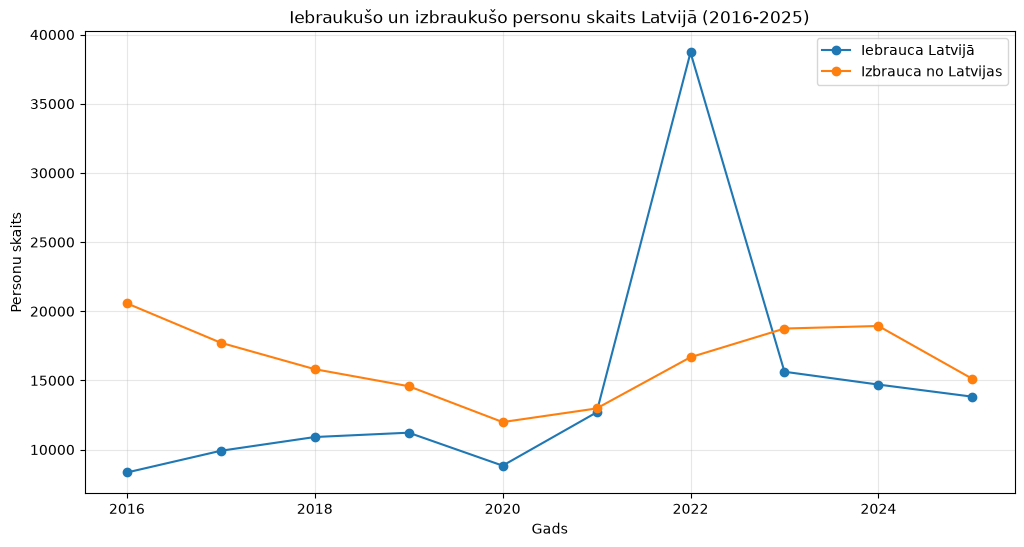

In [5]:
total_migration = country_groups_data[country_groups_data["Valstu grupa"] == "Pavisam"]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    total_migration["Gads"],
    total_migration["Iebrauca Latvijā"],
    marker="o",
    label="Iebrauca Latvijā"
)

ax.plot(
    total_migration["Gads"],
    total_migration["Izbrauca no Latvijas"],
    marker="o",
    label="Izbrauca no Latvijas"
)

ax.set(
    title="Iebraukušo un izbraukušo personu skaits Latvijā (2016-2025)",
    xlabel="Gads",
    ylabel="Personu skaits"
)

ax.legend()
ax.grid(alpha=0.3)

plt.show()

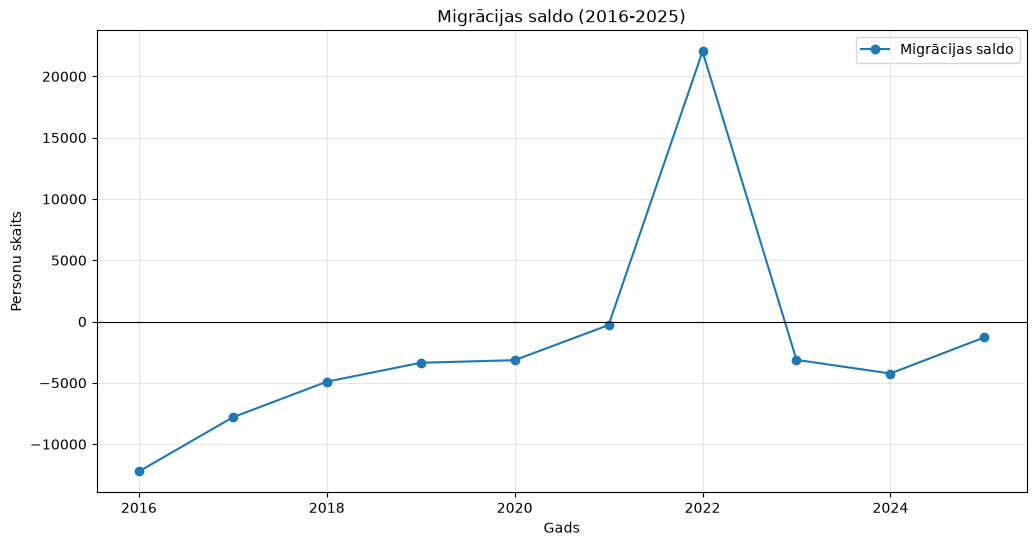

In [6]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    total_migration["Gads"],
    total_migration["Migrācijas saldo"],
    marker="o",
    label="Migrācijas saldo"
)

ax.axhline(0, color="black", linewidth=0.8)

ax.set(
    title="Migrācijas saldo (2016-2025)",
    xlabel="Gads",
    ylabel="Personu skaits"
)

ax.legend()
ax.grid(alpha=0.3)

plt.show()

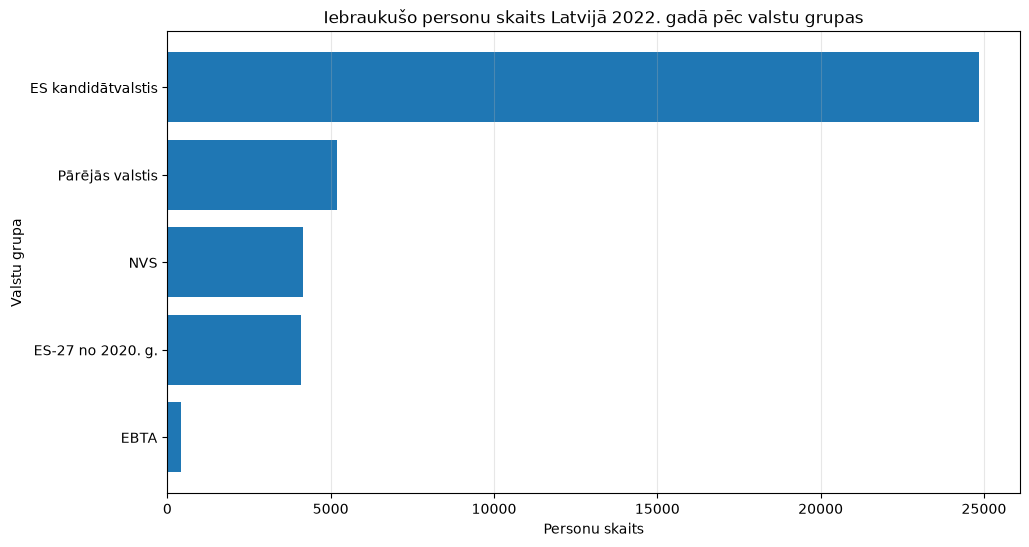

In [7]:
immigration_2022 = country_groups_data[
    (country_groups_data["Gads"] == 2022)
    & (country_groups_data["Valstu grupa"] != "Pavisam")
    & (country_groups_data["Valstu grupa"] != "ES-28")
].sort_values("Iebrauca Latvijā")

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    immigration_2022["Valstu grupa"],
    immigration_2022["Iebrauca Latvijā"]
)

ax.set(
    title="Iebraukušo personu skaits Latvijā 2022. gadā pēc valstu grupas",
    xlabel="Personu skaits",
    ylabel="Valstu grupa"
)

ax.grid(axis="x", alpha=0.3)

plt.show()

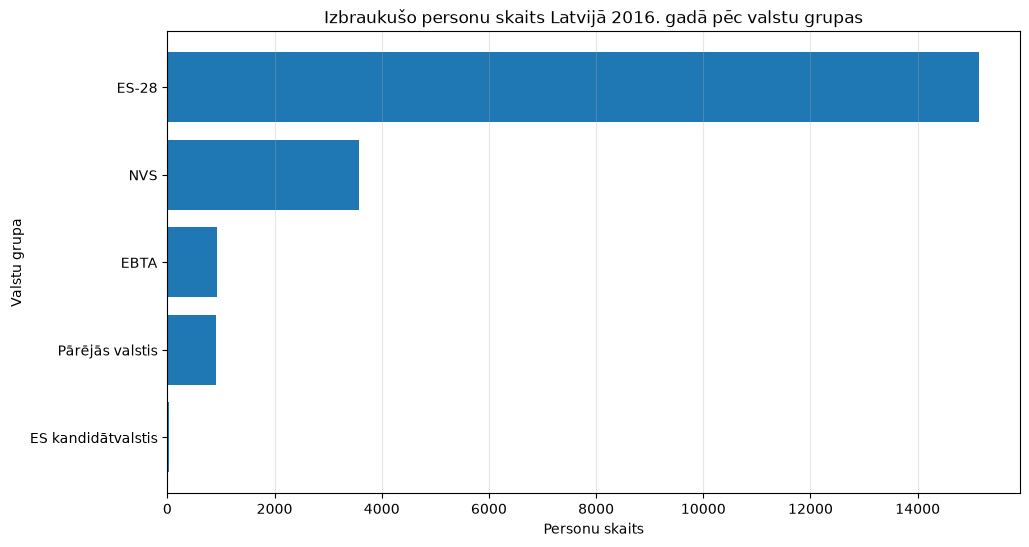

In [8]:
emigration_2016 = country_groups_data[
    (country_groups_data["Gads"] == 2016)
    & (country_groups_data["Valstu grupa"] != "Pavisam")
    & (country_groups_data["Valstu grupa"] != "ES-27 no 2020. g.")
].sort_values("Izbrauca no Latvijas")

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    emigration_2016["Valstu grupa"],
    emigration_2016["Izbrauca no Latvijas"]
)

ax.set(
    title="Izbraukušo personu skaits Latvijā 2016. gadā pēc valstu grupas",
    xlabel="Personu skaits",
    ylabel="Valstu grupa"
)

ax.grid(axis="x", alpha=0.3)

plt.show()

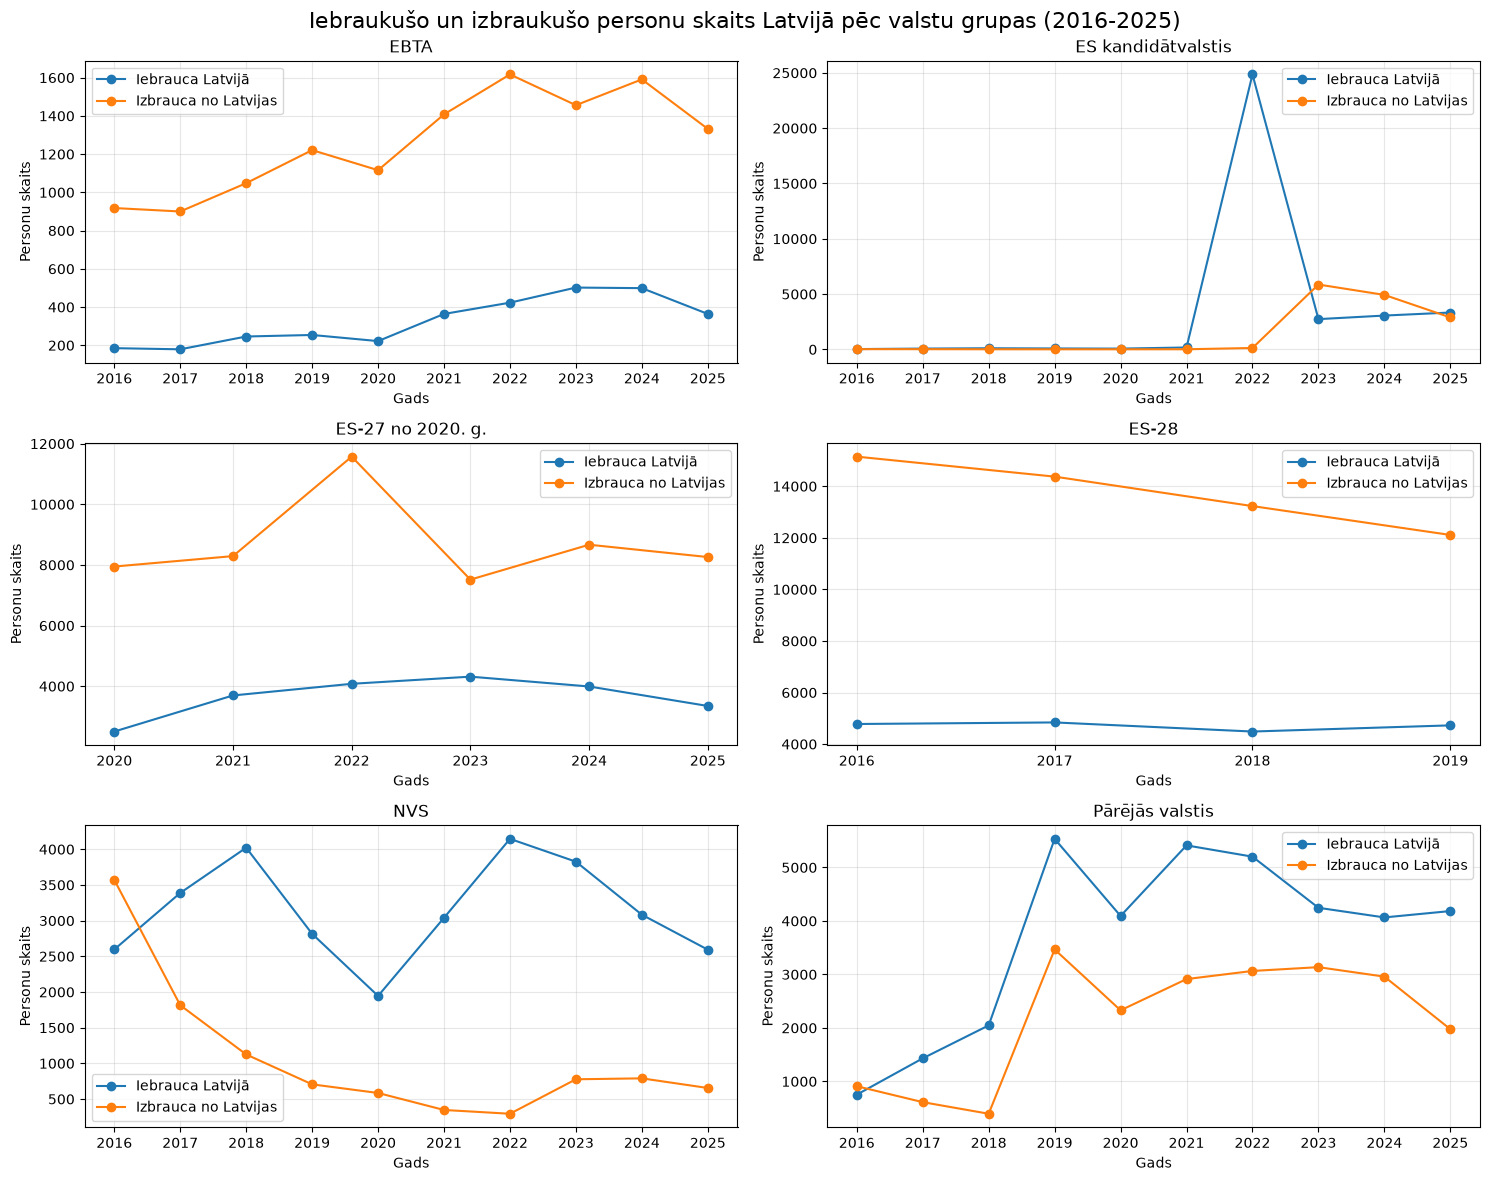

In [9]:
country_groups = country_groups_data.loc[country_groups_data["Valstu grupa"] != "Pavisam", "Valstu grupa"].unique()

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for ax, group in zip(axes.flat, country_groups):
    group_data = country_groups_data[country_groups_data["Valstu grupa"] == group].copy()

    if group == "ES-28":
        group_data = group_data[group_data["Gads"] <= 2019]
    elif group == "ES-27 no 2020. g.":
        group_data = group_data[group_data["Gads"] >= 2020]

    ax.plot(
        group_data["Gads"],
        group_data["Iebrauca Latvijā"],
        marker="o",
        label="Iebrauca Latvijā"
    )
    
    ax.plot(
        group_data["Gads"],
        group_data["Izbrauca no Latvijas"],
        marker="o",
        label="Izbrauca no Latvijas"
    )
    
    ax.set(
        title=group,
        xlabel="Gads",
        ylabel="Personu skaits"
    )

    ax.set_xticks(group_data["Gads"])
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    "Iebraukušo un izbraukušo personu skaits Latvijā pēc valstu grupas (2016-2025)",
    fontsize=16
)

plt.tight_layout()
plt.show()

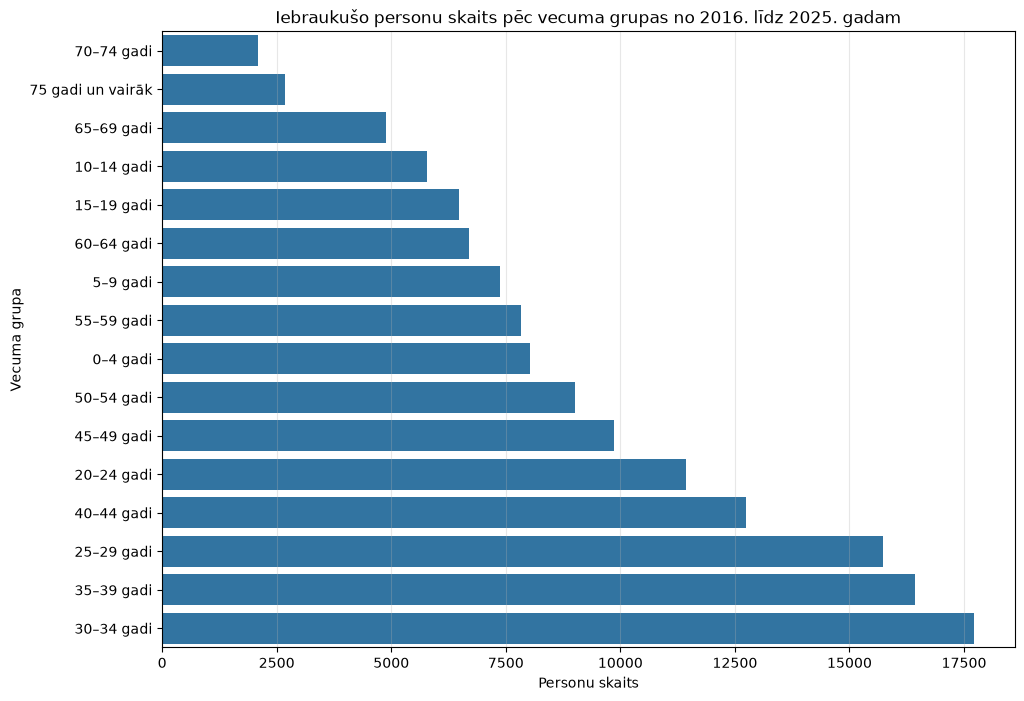

In [10]:
age_groups_arrivals = age_groups_and_sex_data[
    (age_groups_and_sex_data["Dzimums"] == "Pavisam")
    & (age_groups_and_sex_data["Vecuma grupa"] != "Pavisam")
].groupby("Vecuma grupa")["Iebrauca Latvijā"].sum().sort_values()

plt.figure(figsize=(11, 8))

sns.barplot(
    x=age_groups_arrivals.values,
    y=age_groups_arrivals.index
)

plt.title("Iebraukušo personu skaits pēc vecuma grupas no 2016. līdz 2025. gadam")
plt.xlabel("Personu skaits")
plt.ylabel("Vecuma grupa")

plt.grid(axis="x", alpha=0.3)
plt.show()

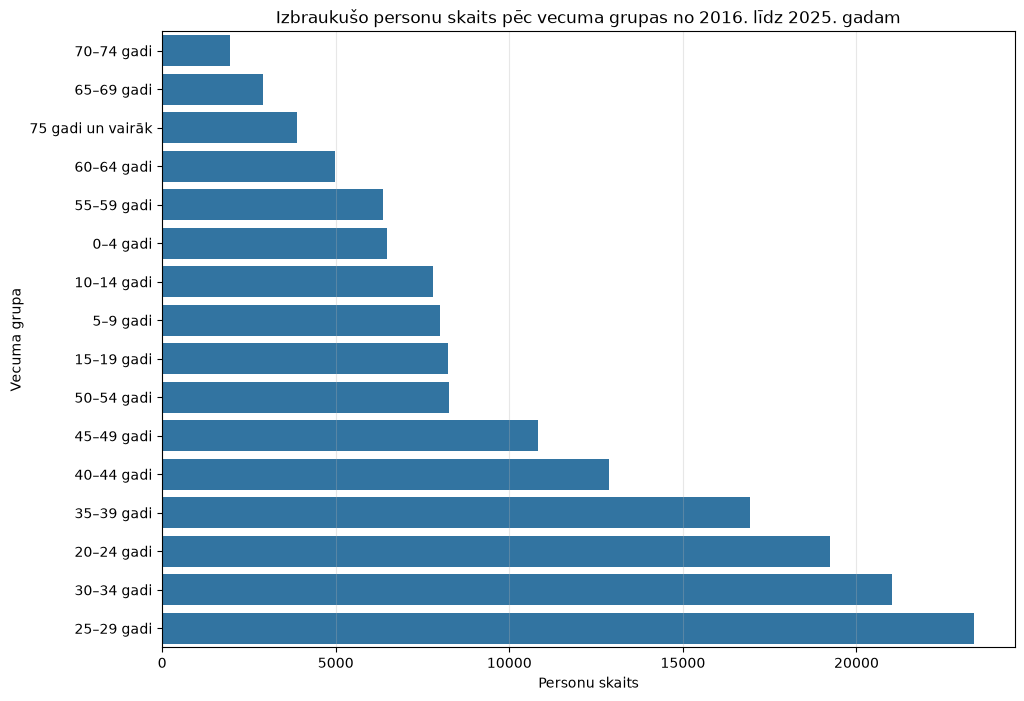

In [11]:
age_groups_departures = age_groups_and_sex_data[
    (age_groups_and_sex_data["Dzimums"] == "Pavisam")
    & (age_groups_and_sex_data["Vecuma grupa"] != "Pavisam")
].groupby("Vecuma grupa")["Izbrauca no Latvijas"].sum().sort_values()

plt.figure(figsize=(11, 8))

sns.barplot(
    x=age_groups_departures.values,
    y=age_groups_departures.index
)

plt.title("Izbraukušo personu skaits pēc vecuma grupas no 2016. līdz 2025. gadam")
plt.xlabel("Personu skaits")
plt.ylabel("Vecuma grupa")

plt.grid(axis="x", alpha=0.3)
plt.show()

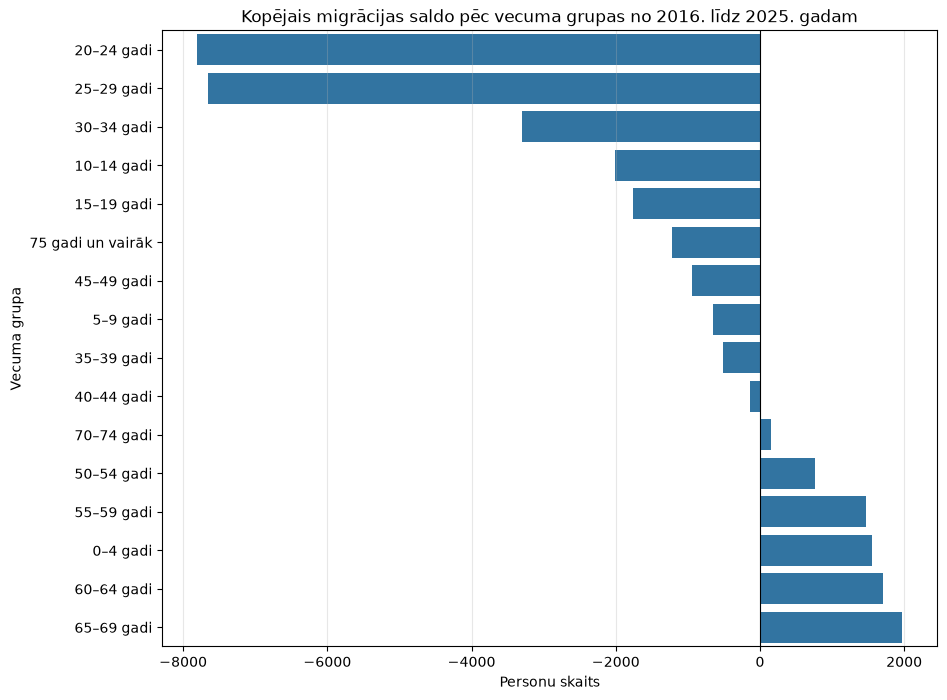

In [12]:
age_groups_saldo = age_groups_and_sex_data[
    (age_groups_and_sex_data["Dzimums"] == "Pavisam")
    & (age_groups_and_sex_data["Vecuma grupa"] != "Pavisam")
].groupby("Vecuma grupa")["Migrācijas saldo"].sum().sort_values()

plt.figure(figsize=(10, 8))

sns.barplot(
    x=age_groups_saldo.values,
    y=age_groups_saldo.index
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Kopējais migrācijas saldo pēc vecuma grupas no 2016. līdz 2025. gadam")
plt.xlabel("Personu skaits")
plt.ylabel("Vecuma grupa")

plt.grid(axis="x", alpha=0.3)
plt.show()

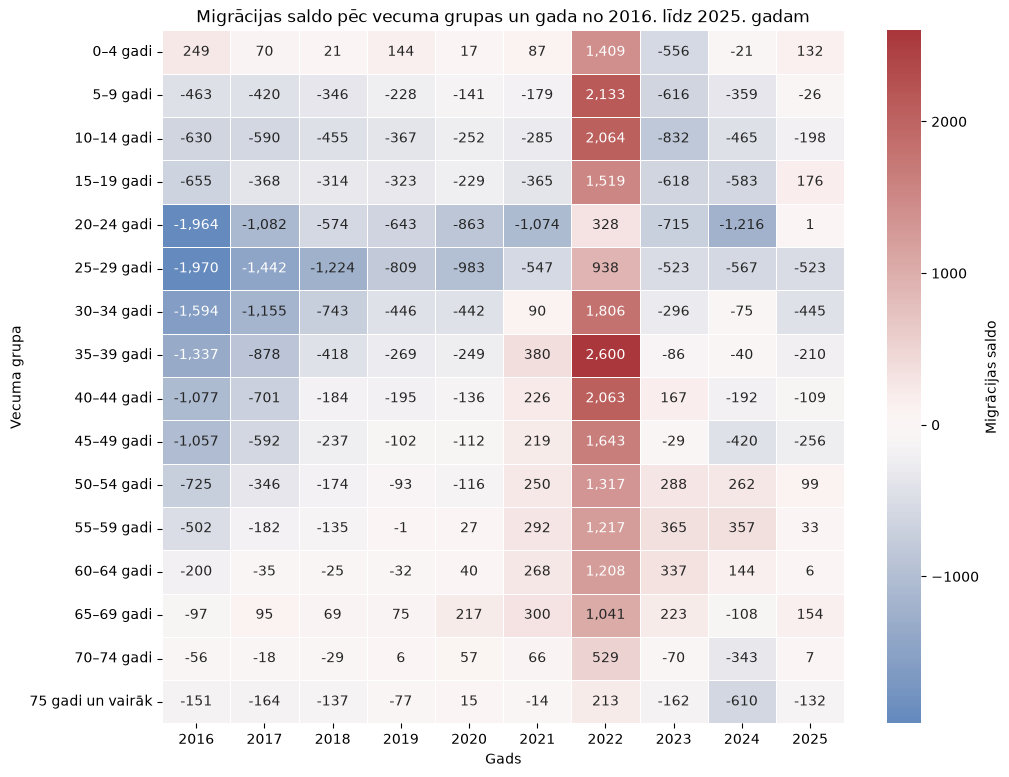

In [13]:
age_groups_saldo_by_year = age_groups_and_sex_data[
    (age_groups_and_sex_data["Dzimums"] == "Pavisam")
    & (age_groups_and_sex_data["Vecuma grupa"] != "Pavisam")
].pivot(
    index="Vecuma grupa",
    columns="Gads",
    values="Migrācijas saldo"
)

age_groups = [
    "0–4 gadi", "5–9 gadi", "10–14 gadi", "15–19 gadi", "20–24 gadi",
    "25–29 gadi", "30–34 gadi", "35–39 gadi", "40–44 gadi", "45–49 gadi",
    "50–54 gadi", "55–59 gadi", "60–64 gadi", "65–69 gadi", "70–74 gadi", "75 gadi un vairāk"
]

age_groups_saldo_by_year = age_groups_saldo_by_year.reindex(age_groups)

plt.figure(figsize=(11, 9))

sns.heatmap(
    age_groups_saldo_by_year,
    annot=True,
    fmt=",",
    center=0,
    cmap="vlag",
    linewidths=0.5,
    cbar_kws={"label": "Migrācijas saldo"}
)

plt.title("Migrācijas saldo pēc vecuma grupas un gada no 2016. līdz 2025. gadam")

plt.show()

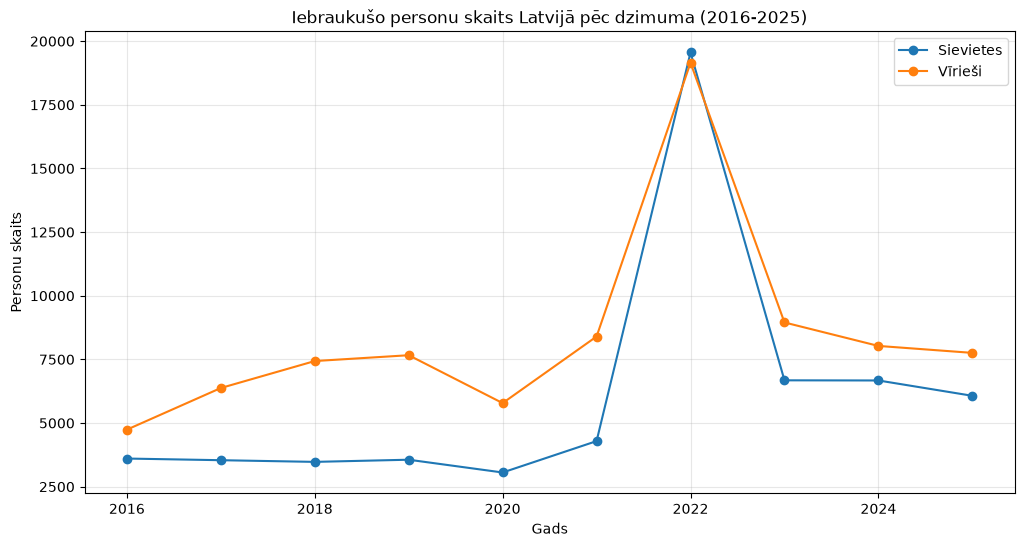

In [14]:
sex_migration = age_groups_and_sex_data[
    (age_groups_and_sex_data["Vecuma grupa"] == "Pavisam")
    & (age_groups_and_sex_data["Dzimums"] != "Pavisam")
]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    sex_migration[sex_migration["Dzimums"] == "Sievietes"]["Gads"],
    sex_migration[sex_migration["Dzimums"] == "Sievietes"]["Iebrauca Latvijā"],
    marker="o",
    label="Sievietes"
)

ax.plot(
    sex_migration[sex_migration["Dzimums"] == "Vīrieši"]["Gads"],
    sex_migration[sex_migration["Dzimums"] == "Vīrieši"]["Iebrauca Latvijā"],
    marker="o",
    label="Vīrieši"
)

ax.set(
    title="Iebraukušo personu skaits Latvijā pēc dzimuma (2016-2025)",
    xlabel="Gads",
    ylabel="Personu skaits"
)

ax.legend()
ax.grid(alpha=0.3)

plt.show()

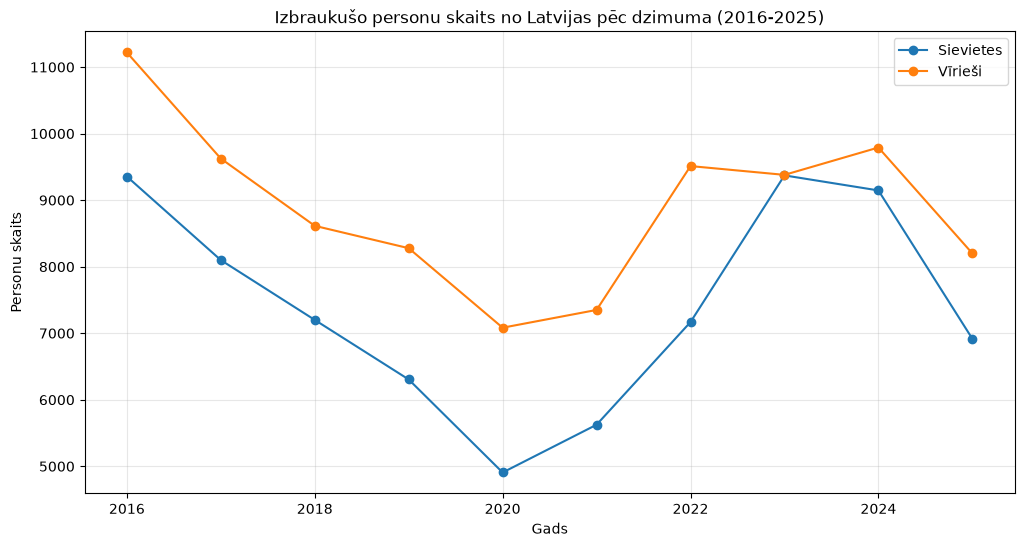

In [15]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    sex_migration[sex_migration["Dzimums"] == "Sievietes"]["Gads"],
    sex_migration[sex_migration["Dzimums"] == "Sievietes"]["Izbrauca no Latvijas"],
    marker="o",
    label="Sievietes"
)

ax.plot(
    sex_migration[sex_migration["Dzimums"] == "Vīrieši"]["Gads"],
    sex_migration[sex_migration["Dzimums"] == "Vīrieši"]["Izbrauca no Latvijas"],
    marker="o",
    label="Vīrieši"
)

ax.set(
    title="Izbraukušo personu skaits no Latvijas pēc dzimuma (2016-2025)",
    xlabel="Gads",
    ylabel="Personu skaits"
)

ax.legend()
ax.grid(alpha=0.3)

plt.show()

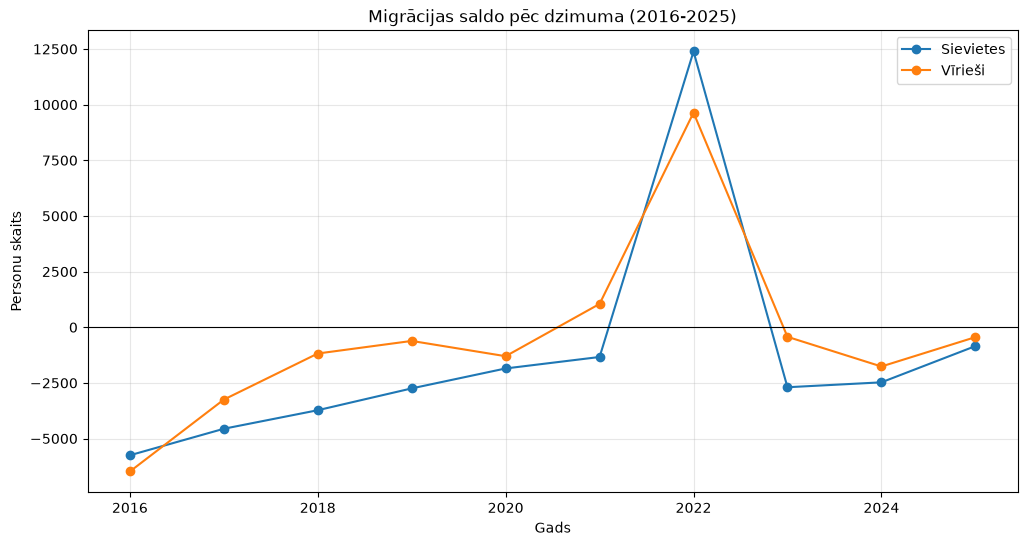

In [16]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    sex_migration[sex_migration["Dzimums"] == "Sievietes"]["Gads"],
    sex_migration[sex_migration["Dzimums"] == "Sievietes"]["Migrācijas saldo"],
    marker="o",
    label="Sievietes"
)

ax.plot(
    sex_migration[sex_migration["Dzimums"] == "Vīrieši"]["Gads"],
    sex_migration[sex_migration["Dzimums"] == "Vīrieši"]["Migrācijas saldo"],
    marker="o",
    label="Vīrieši"
)

ax.axhline(0, color="black", linewidth=0.8)

ax.set(
    title="Migrācijas saldo pēc dzimuma (2016-2025)",
    xlabel="Gads",
    ylabel="Personu skaits"
)

ax.legend()
ax.grid(alpha=0.3)

plt.show()